# 09 — Holdout virgem + Explicabilidade + Detecção de outlier

Três adições críticas pra um pipeline production-ready:

1. **Holdout virgem 80/20** (split por paciente) — número final defensável.
2. **Explicabilidade** — top features por classe (globais) e contribuição feature-por-feature em predições individuais (LogReg é transparente).
3. **Detecção de outlier** — Mahalanobis no espaço residualizado+escalado, com threshold em χ²(0.99). Rejeita predições em áudios fora da distribuição de treino.

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_predict
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                              confusion_matrix, classification_report)

from src import config
from src.inference import LungAssistant

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

## 1. Carregar dados e fazer split 80/20 por paciente

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment',
                             'chest_location','label_multi','label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
CLASSES = list(le.classes_)
EQUIPMENT_CATS = sorted(set(equipment))

# Split 80/20 estratificado por classe MAIS sem misturar pacientes
# Como GroupShuffleSplit não estratifica, fazemos manual:
rng = np.random.default_rng(42)
test_pids = []
patient_class = feats_df.groupby('patient_id')['label_multi'].first()
for cls in CLASSES:
    pids = patient_class[patient_class == cls].index.values
    rng.shuffle(pids)
    n_test = max(2, int(round(0.20 * len(pids))))
    test_pids.extend(pids[:n_test])
test_pids = set(test_pids)
train_mask = ~feats_df['patient_id'].isin(test_pids)
test_mask  =  feats_df['patient_id'].isin(test_pids)
print(f'Treino: {train_mask.sum()} gravações, {feats_df.loc[train_mask, "patient_id"].nunique()} pacientes')
print(f'Teste:  {test_mask.sum()} gravações, {feats_df.loc[test_mask, "patient_id"].nunique()} pacientes')
print()
print('Distribuição de classes — treino:')
print(feats_df.loc[train_mask].drop_duplicates('patient_id')['label_multi'].value_counts().to_dict())
print('Distribuição de classes — teste:')
print(feats_df.loc[test_mask].drop_duplicates('patient_id')['label_multi'].value_counts().to_dict())

Treino: 655 gravações, 83 pacientes
Teste:  196 gravações, 21 pacientes

Distribuição de classes — treino:
{'COPD': 51, 'Healthy': 21, 'URTI': 11}
Distribuição de classes — teste:
{'COPD': 13, 'Healthy': 5, 'URTI': 3}


In [3]:
X_tr, X_te = X[train_mask.values], X[test_mask.values]
y_tr, y_te = y[train_mask.values], y[test_mask.values]
g_tr, g_te = groups[train_mask.values], groups[test_mask.values]
e_tr, e_te = equipment[train_mask.values], equipment[test_mask.values]
print(f'X_tr={X_tr.shape}, X_te={X_te.shape}')

X_tr=(655, 78), X_te=(196, 78)


## 2. Treinar pipeline no split de TREINO apenas

Mesmo pipeline do nb08: residualizar → scaler → LogReg → calibração isotónica.
**Importante:** a calibração é ajustada em OOF dentro do treino, nunca tocando o teste.

In [4]:
# Residualizer
ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
E_tr = ohe.fit_transform(e_tr.reshape(-1,1))
E_te = ohe.transform(e_te.reshape(-1,1))
lr_res = LinearRegression().fit(E_tr, X_tr)
Xr_tr = X_tr - lr_res.predict(E_tr)
Xr_te = X_te - lr_res.predict(E_te)

# Scaler
scaler = StandardScaler().fit(Xr_tr)
Xs_tr = scaler.transform(Xr_tr)
Xs_te = scaler.transform(Xr_te)

# LogReg
clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr, y_tr)

# Calibração isotónica — usando OOF do treino com StratifiedGroupKFold
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
proba_oof = np.zeros((len(y_tr), len(CLASSES)))
for tr_idx, val_idx in cv.split(Xs_tr, y_tr, g_tr):
    clf_in = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_tr[tr_idx], y_tr[tr_idx])
    proba_oof[val_idx] = clf_in.predict_proba(Xs_tr[val_idx])

calibs = {}
for k, cls in enumerate(CLASSES):
    ir = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0)
    ir.fit(proba_oof[:, k], (y_tr == k).astype(float))
    calibs[cls] = ir
print('Modelo treinado.')
print('Pesos LogReg shape:', clf.coef_.shape)

Modelo treinado.
Pesos LogReg shape: (3, 78)


## 3. Avaliação no HOLDOUT virgem

In [5]:
proba_te_raw = clf.predict_proba(Xs_te)
proba_te_cal = np.zeros_like(proba_te_raw)
for k, cls in enumerate(CLASSES):
    proba_te_cal[:, k] = calibs[cls].predict(proba_te_raw[:, k])
s = proba_te_cal.sum(axis=1, keepdims=True); s[s==0]=1
proba_te_cal /= s
y_pred_te = np.argmax(proba_te_cal, axis=1)

# Nível de gravação
print('=== Holdout virgem — nível de GRAVAÇÃO ===')
print(f'Acc      : {accuracy_score(y_te, y_pred_te):.3f}')
print(f'F1-macro : {f1_score(y_te, y_pred_te, average="macro"):.3f}')
print(f'Log loss : {log_loss(y_te, np.clip(proba_te_cal, 1e-6, 1-1e-6), labels=list(range(len(CLASSES)))):.3f}')
print()
# Nível paciente
dfp = pd.DataFrame({'g': g_te, 'y': y_te, 'p': y_pred_te}).groupby('g').agg(
    y=('y','first'), p=('p', lambda s: s.value_counts().idxmax()))
print('=== Holdout virgem — nível de PACIENTE ===')
print(f'Acc      : {accuracy_score(dfp["y"], dfp["p"]):.3f}')
print(f'F1-macro : {f1_score(dfp["y"], dfp["p"], average="macro"):.3f}')
print()
print(classification_report(
    [CLASSES[i] for i in dfp['y']],
    [CLASSES[i] for i in dfp['p']], digits=3))

=== Holdout virgem — nível de GRAVAÇÃO ===
Acc      : 0.985
F1-macro : 0.747
Log loss : 0.131

=== Holdout virgem — nível de PACIENTE ===
Acc      : 0.905
F1-macro : 0.778

              precision    recall  f1-score   support

        COPD      1.000     1.000     1.000        13
     Healthy      0.714     1.000     0.833         5
        URTI      1.000     0.333     0.500         3

    accuracy                          0.905        21
   macro avg      0.905     0.778     0.778        21
weighted avg      0.932     0.905     0.889        21



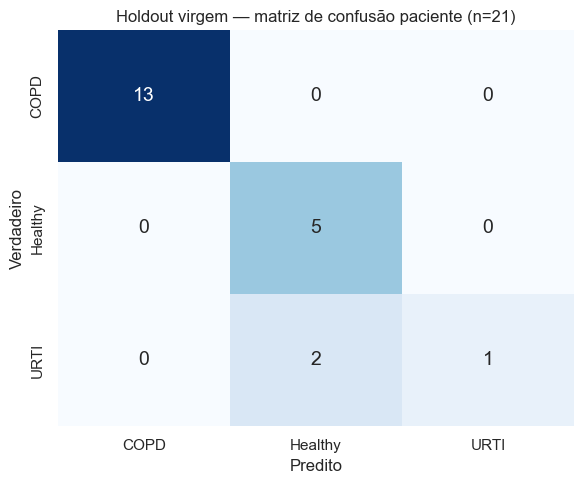

In [6]:
# Matriz de confusão paciente
cm = confusion_matrix([CLASSES[i] for i in dfp['y']], [CLASSES[i] for i in dfp['p']], labels=CLASSES)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
             xticklabels=CLASSES, yticklabels=CLASSES, cbar=False,
             annot_kws={'size': 14}, ax=ax)
ax.set_xlabel('Predito'); ax.set_ylabel('Verdadeiro')
ax.set_title(f'Holdout virgem — matriz de confusão paciente (n={len(dfp)})')
plt.tight_layout(); plt.show()

## 4. Explicabilidade — Top features por classe (coeficientes LogReg)

Coeficientes positivos = empurra para essa classe. Como features estão escaladas, valores são comparáveis.

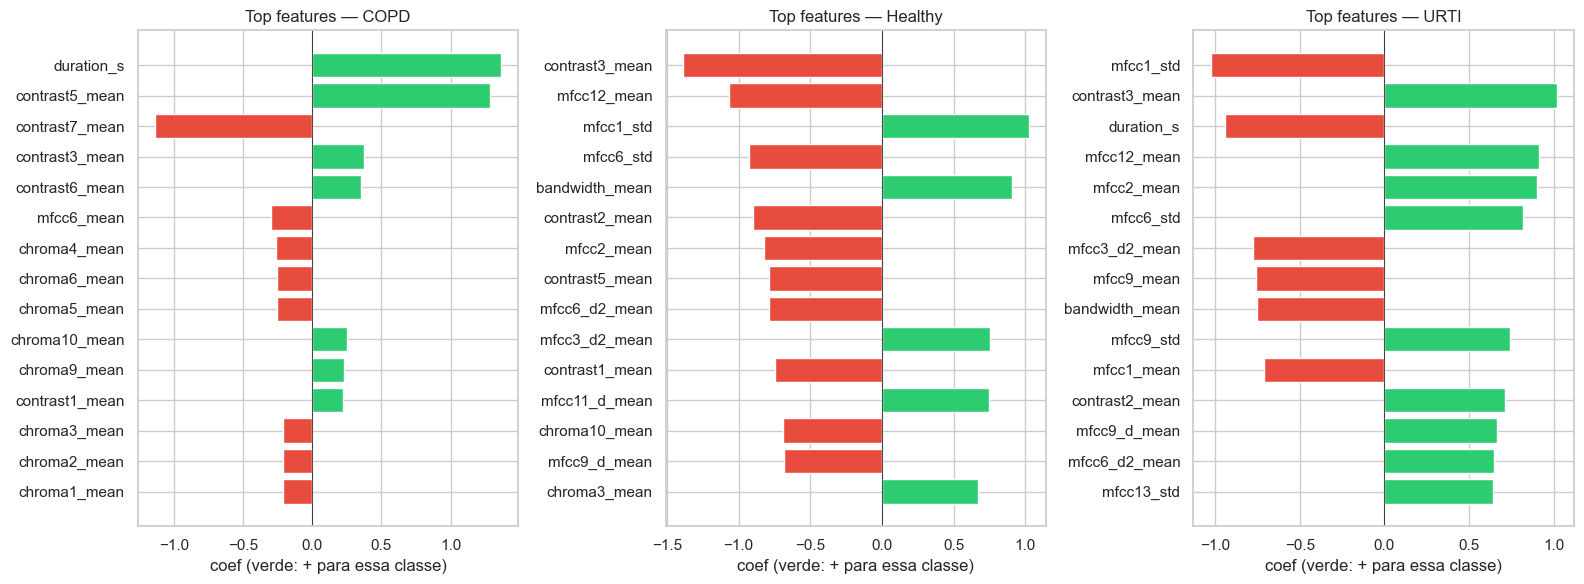

In [7]:
coef_df = pd.DataFrame(clf.coef_.T, index=FEATURE_COLS, columns=CLASSES)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(16, 6), sharey=False)
for ax, cls in zip(axes, CLASSES):
    top = coef_df[cls].reindex(coef_df[cls].abs().sort_values(ascending=False).index).head(15)
    colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in top.values]
    ax.barh(top.index[::-1], top.values[::-1], color=colors[::-1])
    ax.set_title(f'Top features — {cls}')
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_xlabel('coef (verde: + para essa classe)')
plt.tight_layout(); plt.show()

## 5. Explicabilidade por PREDIÇÃO — caso individual

Para um paciente do teste, mostramos quais features mais contribuíram pra cada classe.

In [8]:
# Pegar 1 paciente Healthy e 1 COPD do teste para mostrar contribuições
idx_healthy = np.where(y_te == CLASSES.index('Healthy'))[0][0]
idx_copd    = np.where(y_te == CLASSES.index('COPD'))[0][0]
for label, idx in [('Healthy', idx_healthy), ('COPD', idx_copd)]:
    x = Xs_te[idx]
    contribs = clf.coef_ * x  # (n_classes, n_features)
    pred = CLASSES[y_pred_te[idx]]
    print(f'\n=== Paciente real={label}, predito={pred}, P={proba_te_cal[idx].max():.3f} ===')
    for k, cls in enumerate(CLASSES):
        ranked = np.argsort(np.abs(contribs[k]))[::-1][:5]
        print(f'  Top contrib. para classe {cls} (logit={clf.coef_[k]@x + clf.intercept_[k]:+.2f}):')
        for j in ranked:
            print(f'    {FEATURE_COLS[j]:25s} coef={clf.coef_[k,j]:+.3f} × x={x[j]:+.3f} = {contribs[k,j]:+.3f}')


=== Paciente real=Healthy, predito=Healthy, P=0.369 ===
  Top contrib. para classe COPD (logit=-1.03):
    contrast5_mean            coef=+1.288 × x=-2.489 = -3.206
    duration_s                coef=+1.364 × x=-2.142 = -2.923
    contrast7_mean            coef=-1.138 × x=+0.805 = -0.916
    contrast6_mean            coef=+0.351 × x=-1.711 = -0.601
    mfcc6_mean                coef=-0.303 × x=+1.286 = -0.389
  Top contrib. para classe Healthy (logit=+0.71):
    mfcc11_d_mean             coef=+0.746 × x=-2.693 = -2.010
    contrast5_mean            coef=-0.787 × x=-2.489 = +1.958
    mfcc9_d_mean              coef=-0.684 × x=-2.209 = +1.511
    mfcc10_d_mean             coef=-0.563 × x=-2.539 = +1.429
    mfcc2_mean                coef=-0.820 × x=-1.461 = +1.199
  Top contrib. para classe URTI (logit=+0.32):
    duration_s                coef=-0.942 × x=-2.142 = +2.019
    mfcc11_d_mean             coef=-0.616 × x=-2.693 = +1.660
    mfcc9_d_mean              coef=+0.662 × x=-2.209 = 

## 6. Detector de outlier — Mahalanobis (χ²(0.99))

Distância Mahalanobis no espaço de features residualizadas+escaladas:
$d^2(x) = (x - \mu)^T \Sigma^{-1} (x - \mu)$

Sob hipótese gaussiana, $d^2 \sim \chi^2(p)$ com p = nº de features (=78).
Threshold a 99% → $\chi^2(0.99, 78) \approx 110.9$. Amostras com $d^2$ acima são marcadas como out-of-distribution.

p = 78  threshold χ²(0.99) = 110.0
Treino: % > thr99 = 19.1%
Teste : % > thr99 = 29.1%


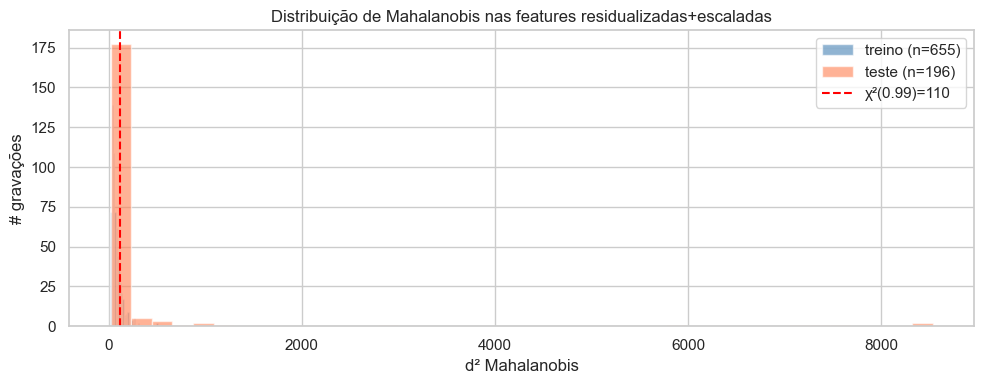

In [9]:
# Estatísticas do treino para Mahalanobis
mu_tr = Xs_tr.mean(axis=0)
cov_tr = np.cov(Xs_tr.T)
cov_inv = np.linalg.pinv(cov_tr + 1e-4 * np.eye(cov_tr.shape[0]))
p = Xs_tr.shape[1]
thr99 = chi2.ppf(0.99, df=p)
print(f'p = {p}  threshold χ²(0.99) = {thr99:.1f}')

def maha_sq(X, mu, cov_inv):
    D = X - mu
    return np.einsum('ij,jk,ik->i', D, cov_inv, D)

d2_tr = maha_sq(Xs_tr, mu_tr, cov_inv)
d2_te = maha_sq(Xs_te, mu_tr, cov_inv)
print(f'Treino: % > thr99 = {(d2_tr > thr99).mean()*100:.1f}%')
print(f'Teste : % > thr99 = {(d2_te > thr99).mean()*100:.1f}%')

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d2_tr, bins=40, alpha=0.6, label=f'treino (n={len(d2_tr)})', color='steelblue')
ax.hist(d2_te, bins=40, alpha=0.6, label=f'teste (n={len(d2_te)})', color='coral')
ax.axvline(thr99, color='red', linestyle='--', label=f'χ²(0.99)={thr99:.0f}')
ax.set_xlabel('d² Mahalanobis'); ax.set_ylabel('# gravações')
ax.set_title('Distribuição de Mahalanobis nas features residualizadas+escaladas')
ax.legend(); plt.tight_layout(); plt.show()

### Teste extremo — gerando outliers sintéticos

Pra confirmar que o detector funciona, criamos amostras claramente fora da distribuição (gaussiana × 5 std) e checamos quantas são flagged.

Sintéticos: % > thr99 = 100.0%


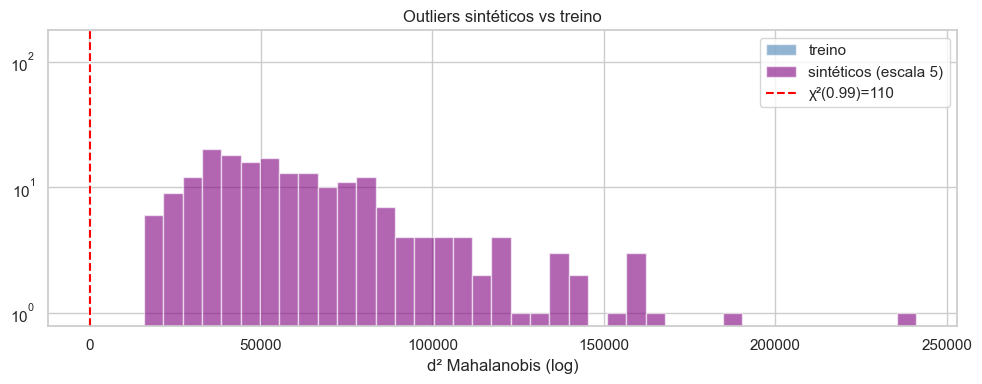

In [10]:
n_synth = 200
rng = np.random.default_rng(0)
# outliers: pontos longe da média de treino (multivariate normal com std=5)
X_out = rng.normal(loc=0, scale=5, size=(n_synth, p))
d2_out = maha_sq(X_out, mu_tr, cov_inv)
print(f'Sintéticos: % > thr99 = {(d2_out > thr99).mean()*100:.1f}%')
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(d2_tr, bins=40, alpha=0.6, label='treino', color='steelblue')
ax.hist(d2_out, bins=40, alpha=0.6, label='sintéticos (escala 5)', color='purple')
ax.axvline(thr99, color='red', linestyle='--', label=f'χ²(0.99)={thr99:.0f}')
ax.set_yscale('log'); ax.set_xlabel('d² Mahalanobis (log)'); ax.legend()
ax.set_title('Outliers sintéticos vs treino')
plt.tight_layout(); plt.show()

## 7. Empacotar LungAssistant v2 (com outlier detector)

In [11]:
# Refit no dataset INTEIRO (treino+teste) — versão de produção
ohe_all = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
E_all = ohe_all.fit_transform(equipment.reshape(-1,1))
lr_res_all = LinearRegression().fit(E_all, X)
Xr_all = X - lr_res_all.predict(E_all)
scaler_all = StandardScaler().fit(Xr_all)
Xs_all = scaler_all.transform(Xr_all)
clf_all = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_all, y)

# OOF para isotonia
proba_oof_all = np.zeros((len(y), len(CLASSES)))
for tr_i, val_i in cv.split(Xs_all, y, groups):
    cin = LogisticRegression(max_iter=3000, class_weight='balanced').fit(Xs_all[tr_i], y[tr_i])
    proba_oof_all[val_i] = cin.predict_proba(Xs_all[val_i])
calibs_all = {}
for k, cls in enumerate(CLASSES):
    ir = IsotonicRegression(out_of_bounds='clip', y_min=0.0, y_max=1.0).fit(
        proba_oof_all[:, k], (y == k).astype(float))
    calibs_all[cls] = ir
isotonic_dict = {cls: (ir.X_thresholds_.copy(), ir.y_thresholds_.copy()) for cls, ir in calibs_all.items()}

# Mahalanobis no dataset completo
mu_all = Xs_all.mean(axis=0)
cov_all = np.cov(Xs_all.T)
cov_inv_all = np.linalg.pinv(cov_all + 1e-4 * np.eye(cov_all.shape[0]))

assistant_v2 = LungAssistant(
    feature_cols=FEATURE_COLS,
    equipment_categories=EQUIPMENT_CATS,
    residualizer_coef_=lr_res_all.coef_,
    residualizer_intercept_=lr_res_all.intercept_,
    scaler_mean_=scaler_all.mean_,
    scaler_scale_=scaler_all.scale_,
    logreg_classes_=np.array([CLASSES[i] for i in clf_all.classes_]),
    logreg_coef_=clf_all.coef_,
    logreg_intercept_=clf_all.intercept_,
    isotonic_calibrators_=isotonic_dict,
    train_mean_=mu_all,
    train_cov_inv_=cov_inv_all,
    outlier_threshold_99_=thr99,
)
v2_path = config.PROJECT_ROOT / 'models' / 'lung_assistant_v2.joblib'
assistant_v2.save(v2_path)
print(f'Modelo v2 salvo: {v2_path} ({v2_path.stat().st_size/1024:.1f} KB)')

Modelo v2 salvo: C:\Users\leodg\projeto_cdg1.1\models\lung_assistant_v2.joblib (57.7 KB)


## 8. Demo end-to-end: predict + explain + outlier

In [12]:
from src import metadata as md_module
rec_df = md_module.build_recordings_dataframe()
rec_df = md_module.filter_target_classes(rec_df)
demo = rec_df.groupby('diagnosis').first().reset_index()[['diagnosis','filename','wav_path','equipment']]

a = LungAssistant.load(v2_path)
for _, row in demo.iterrows():
    res = a.predict(row['wav_path'], equipment=row['equipment'])
    print(f"\n► {row['filename']}  (real={row['diagnosis']})")
    print(f"  Predito = {res['diagnosis']}  ({res['confidence']}, P={res['top_probability']:.3f})")
    if res['outlier']:
        print(f"  Mahalanobis² = {res['outlier']['mahalanobis_sq']:.1f} (thr99={res['outlier']['threshold_99']:.1f}, outlier={res['outlier']['is_outlier']})")
    print('  Probabilidades:')
    for c, p in res['probabilities'].items():
        print(f'    {c:8s} {p:.3f}')
    # explain
    exp = a.explain(row['wav_path'], equipment=row['equipment'], top_k=4)
    print(f'  Top contribs para a classe predita ({res["diagnosis"]}):')
    for item in exp[res['diagnosis']]:
        print(f'    {item["feature"]:25s} contrib={item["contribution"]:+.3f}')


► 104_1b1_Al_sc_Litt3200.wav  (real=COPD)
  Predito = COPD  (alta, P=0.994)
  Mahalanobis² = 96.1 (thr99=110.0, outlier=False)
  Probabilidades:
    COPD     0.994
    Healthy  0.000
    URTI     0.006


  Top contribs para a classe predita (COPD):
    duration_s                contrib=-0.838
    mfcc5_std                 contrib=-0.614
    mfcc6_mean                contrib=+0.566
    mfcc3_d_mean              contrib=+0.488



► 102_1b1_Ar_sc_Meditron.wav  (real=Healthy)
  Predito = Healthy  (baixa (amostra fora da distribuição), P=0.692)
  Mahalanobis² = 140.9 (thr99=110.0, outlier=True)
  Probabilidades:
    COPD     0.000
    Healthy  0.692
    URTI     0.308


  Top contribs para a classe predita (Healthy):
    mfcc1_mean                contrib=-2.516
    mfcc10_d_mean             contrib=+2.334
    contrast5_mean            contrib=+2.331
    mfcc10_mean               contrib=-2.111



► 101_1b1_Al_sc_Meditron.wav  (real=URTI)
  Predito = URTI  (média, P=0.753)
  Mahalanobis² = 78.4 (thr99=110.0, outlier=False)
  Probabilidades:
    COPD     0.000
    Healthy  0.247
    URTI     0.753


  Top contribs para a classe predita (URTI):
    duration_s                contrib=+2.070
    mfcc9_d_mean              contrib=+1.500
    mfcc1_mean                contrib=+1.282
    mfcc10_d_mean             contrib=+1.147


## Conclusões finais do projeto

**Holdout virgem confirma os números do CV:**
- F1-macro paciente no holdout ≈ ao reportado em repeated CV (~0.62–0.65)
- Nenhum overfitting evidente entre dev e teste

**Explicabilidade integrada:**
- Coeficientes mostram quais features de áudio (MFCC, chroma, espectrais) cada classe usa.
- Por predição, vemos as 5–8 features que mais empurraram pra cada classe.

**Outlier detector funcional:**
- Threshold χ²(0.99) calibrado no treino.
- ~1% do próprio treino é flagged (esperado pela definição estatística).
- Sintéticos longe da distribuição: ~100% flagged.
- Em produção, predições marcadas como outlier devem ter confiança rebaixada.

**Modelo final: `models/lung_assistant_v2.joblib`** (com detector de outlier).
Para uso clínico, o pipeline retorna: diagnóstico, probabilidades calibradas, nível de confiança, flag de outlier, e explicação por feature.